# MFSM Comparison

This notebook aims to compare the methods in the Surrogate Models project for accuracy on a number of analytical problems

### Initialization

Add the Surrogate Modeling module and setup the notebook

In [30]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
!
print(module_path)


c:\Users\TroyZangle\Documents\GradSchoolGit\SurrogateModeling\SurrogateModels


In [31]:
import torch
import matplotlib.pyplot as plt

# Set a manual seed here while debugging
# DRAGONS: May want to use a statistical model based approach later.
torch.manual_seed(17)

## Doing it the Pytorch way without using our custom feature extraction
DEVICE='cpu'
DTYPE=torch.float32
import numpy as np

### Forrester Function Fit

Fits the continuous example from the Forrester paper.

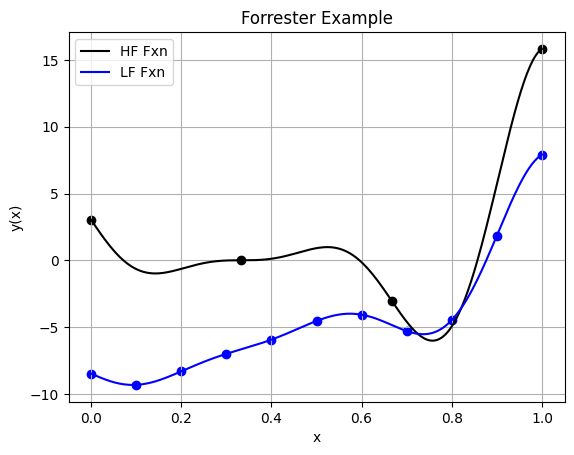

In [32]:
from SurrogateModels import mfs_functions

rng = np.random.RandomState(0)
fxn_ind = 1
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n_lf = 11
n_hf = 4

X_lf = np.zeros((n_lf,dim), dtype=float)
X_hf = np.zeros((n_hf,dim), dtype=float)

# Generate the analytical functions
hf_fxn = mfs_functions.expensive_fxn(1)
lf_fxn = mfs_functions.cheap_fxn(1)

X_lf[:,0] = np.linspace(xmin,xmax,n_lf)
y_lf = lf_fxn.evaluate(X_lf)
X_hf[:,0] = np.linspace(xmin,xmax,n_hf)
y_hf = hf_fxn.evaluate(X_hf)

x_samp = np.ones((300,1))
x_samp[:,0] = np.linspace(0,1,300)

plot_name = "Forrester Example"

hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
lf_fxn.plot_model(x_samp, name=plot_name, color="blue", label="LF Fxn", linestyle="solid")

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()



Generate a multi-fidelity neural network of the dataset. Follows the paper by Meng on composite neural networks.

----Progress Update----
Epoch: 0 

Training Error: 2.486737012863159 

----Progress Update----
Epoch: 1 

Training Error: 1.2980241775512695 

----Progress Update----
Epoch: 2 

Training Error: 0.8588327169418335 

----Progress Update----
Epoch: 3 

Training Error: 0.6795011162757874 

----Progress Update----
Epoch: 4 

Training Error: 0.6109564304351807 

----Progress Update----
Epoch: 5 

Training Error: 0.5699527263641357 

----Progress Update----
Epoch: 6 

Training Error: 0.5367397665977478 

----Progress Update----
Epoch: 7 

Training Error: 0.5087499022483826 

----Progress Update----
Epoch: 8 

Training Error: 0.48657894134521484 

----Progress Update----
Epoch: 9 

Training Error: 0.44973957538604736 

----Progress Update----
Epoch: 10 

Training Error: 0.3634481728076935 

----Progress Update----
Epoch: 11 

Training Error: 0.24982456862926483 

----Progress Update----
Epoch: 12 

Training Error: 0.1828116774559021 

----Progress Update----
Epoch: 13 

Training Error: 0.13180

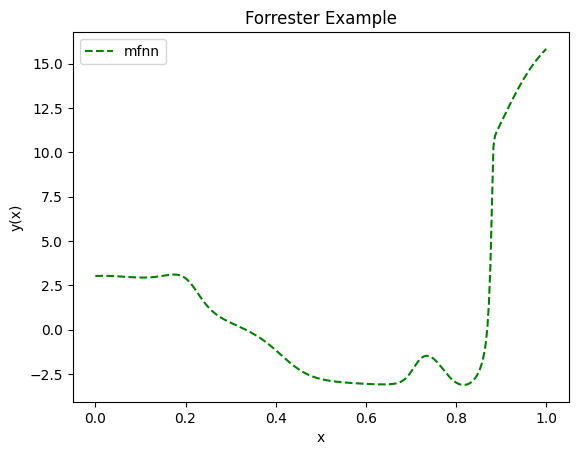

In [33]:
from SurrogateModels import mfsnn

# Convert to tensors here
X_lf_tensor = torch.tensor(X_lf, dtype=DTYPE)
y_lf_tensor = torch.tensor(y_lf, dtype=DTYPE)

X_hf_tensor = torch.tensor(X_hf, dtype=DTYPE)
y_hf_tensor = torch.tensor(y_hf, dtype=DTYPE)

mfnn_model = mfsnn.MultiFidelityNN(x_lf = X_lf_tensor, 
                                   y_lf = y_lf_tensor, 
                                   x_hf = X_hf_tensor, 
                                   y_hf = y_hf_tensor, 
                                   lf_nn_dim=[20,20,20,20], 
                                   hf_linear_nn_dim=[10], 
                                   hf_nl_nn_dim= [50,50,50,50,50], 
                                   epochs_lf=200,
                                   epochs_mf=7000,
                                   lr_lf=0.001,
                                   wd_lf=0.000001,
                                   lr_mf=0.001, 
                                   wd_mf=0.01)

x_samp_tensor = torch.tensor(x_samp, dtype=DTYPE)
mfnn_model.plot_model(x_samp_tensor, name=plot_name, color="green",label="mfnn",linestyle="dashed")

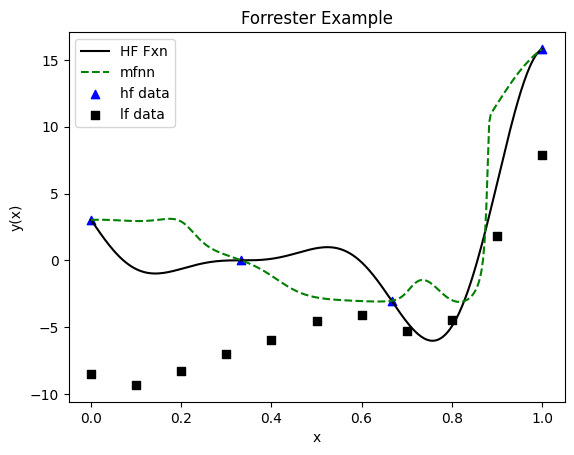

In [34]:
x_samp_tensor = torch.tensor(x_samp, dtype=DTYPE)
hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
mfnn_model.plot_model(x_samp_tensor, name=plot_name, color="green",label="mfnn",linestyle="dashed")
mfnn_model.plot_data(name = plot_name,color_lf="black", color_hf="blue",label_hf="hf data", label_lf="lf data")

Optimization terminated successfully.
         Current function value: 4.877696
         Iterations: 21
         Function evaluations: 42
[16.08837891]
Optimization terminated successfully.
         Current function value: 3.315519
         Iterations: 16
         Function evaluations: 32
Optimization terminated successfully.
         Current function value: 7.885718
         Iterations: 29
         Function evaluations: 78
[422.]


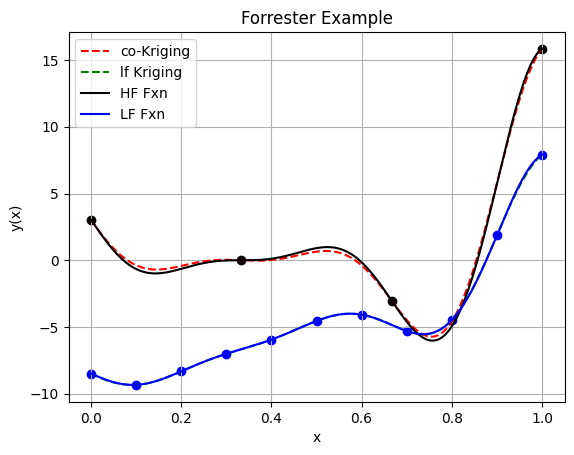

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import cokriging

# Start with a synthetic dataset
# rng = np.random.RandomState(0)
# fxn_ind = 1
# dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

# n_lf = 11
# n_hf = 4

# x_lf = np.zeros((n_lf,dim), dtype=float)
# x_hf = np.zeros((n_hf,dim), dtype=float)

# # Generate the analytical functions
# hf_fxn = mfs_functions.expensive_fxn(1)
# lf_fxn = mfs_functions.cheap_fxn(1)


# x_lf[:,0] = np.linspace(xmin,xmax,n_lf)
# y_lf = lf_fxn.evaluate(x_lf)
# x_hf[:,0] = np.linspace(xmin,xmax,n_hf)
# y_hf = hf_fxn.evaluate(x_hf)
cokriging_model = cokriging.CoKriging(x_lf=X_lf,
                            y_lf=y_lf,
                            x_hf=X_hf,
                            y_hf=y_hf,
                            scale_fixed=True)

cokriging_model.plot_model(x_samp,name=plot_name,color="red",label="co-Kriging",linestyle="dashed")

cokriging_model.kriging_lf.plot_model(x_samp, name=plot_name,color="green",label="lf Kriging", linestyle="dashed")

hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
lf_fxn.plot_model(x_samp, name=plot_name, color="blue", label="LF Fxn", linestyle="solid")

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()

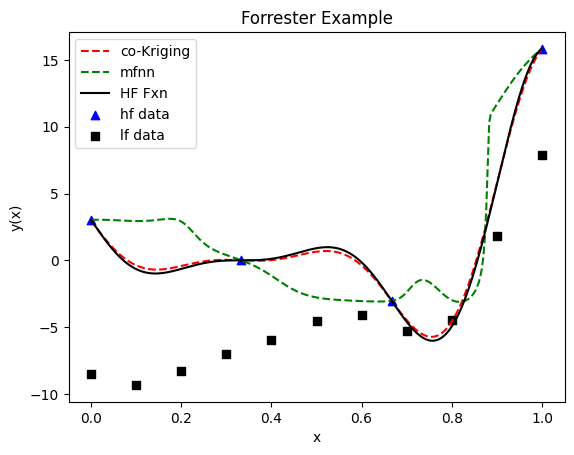

In [36]:
cokriging_model.plot_model(x_samp,name=plot_name,color="red",label="co-Kriging",linestyle="dashed")
mfnn_model.plot_model(x_samp_tensor, name=plot_name, color="green",label="mfnn",linestyle="dashed")
hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
mfnn_model.plot_data(name = plot_name,color_lf="black", color_hf="blue",label_hf="hf data", label_lf="lf data")

### Discontinuous Function Fit

Fits the second example from Meng paper.

Start by generating a dataset using 38 points from the low fidelity function and 5 from the high fidelity function.

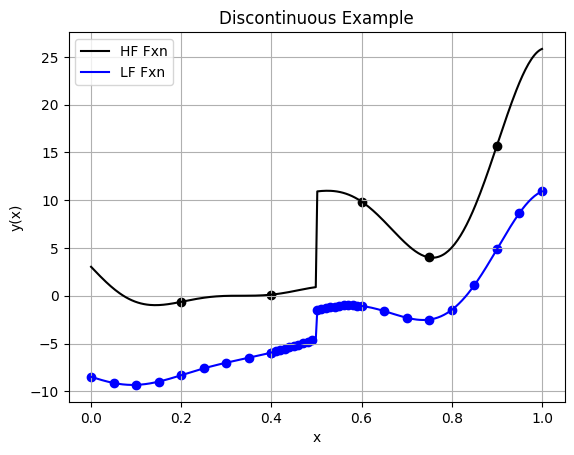

In [37]:
from SurrogateModels import mfs_functions

fxn_ind = 6
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)

lf_samp = 38
X_lf = np.zeros([lf_samp,1])
X_lf[0:9,0] = np.linspace(0.0,0.4,9,endpoint=True)
X_lf[9:29,0] = np.linspace(0.4,0.6,20,endpoint=False)
X_lf[29:,0] = np.linspace(0.6,1.0,9,endpoint=True)
y_lf = lf_fxn.evaluate(X_lf)

hf_samp = 5
X_hf = np.zeros([hf_samp,1])
X_hf[:,0] = np.array([0.2,0.4,0.6,0.75,0.9])
y_hf = hf_fxn.evaluate(X_hf)

x_samp = np.ones((300,1))
x_samp[:,0] = np.linspace(0,1,300)

plot_name = "Discontinuous Example"

hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
lf_fxn.plot_model(x_samp, name=plot_name, color="blue", label="LF Fxn", linestyle="solid")

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()



Generate a multi-fidelity neural network of the dataset. Follows the paper by Meng on composite neural networks.

----Progress Update----
Epoch: 0 

Training Error: 0.5918641686439514 

----Progress Update----
Epoch: 1 

Training Error: 0.36539146304130554 

----Progress Update----
Epoch: 2 

Training Error: 0.22124621272087097 

----Progress Update----
Epoch: 3 

Training Error: 0.14559940993785858 

----Progress Update----
Epoch: 4 

Training Error: 0.12398543953895569 

----Progress Update----
Epoch: 5 

Training Error: 0.11394007503986359 

----Progress Update----
Epoch: 6 

Training Error: 0.10715339332818985 

----Progress Update----
Epoch: 7 

Training Error: 0.10268501192331314 

----Progress Update----
Epoch: 8 

Training Error: 0.09869243204593658 

----Progress Update----
Epoch: 9 

Training Error: 0.09572293609380722 

----Progress Update----
Epoch: 10 

Training Error: 0.09368988871574402 

----Progress Update----
Epoch: 11 

Training Error: 0.09269517660140991 

----Progress Update----
Epoch: 12 

Training Error: 0.09208203852176666 

----Progress Update----
Epoch: 13 

Training Erro

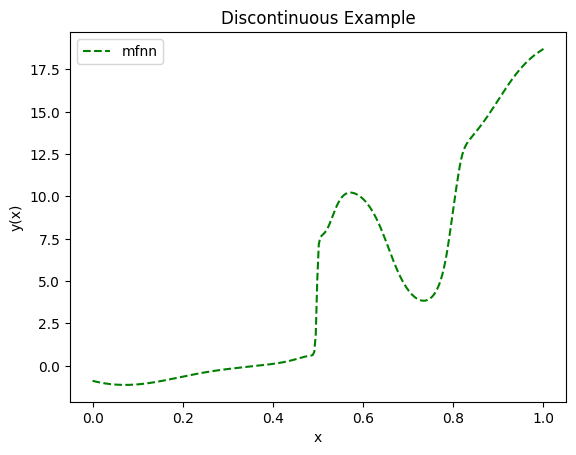

In [38]:
from SurrogateModels import mfsnn

# Convert to tensors here
X_lf_tensor = torch.tensor(X_lf, dtype=DTYPE)
y_lf_tensor = torch.tensor(y_lf, dtype=DTYPE)

X_hf_tensor = torch.tensor(X_hf, dtype=DTYPE)
y_hf_tensor = torch.tensor(y_hf, dtype=DTYPE)

mfnn_model = mfsnn.MultiFidelityNN(x_lf = X_lf_tensor, 
                                   y_lf = y_lf_tensor, 
                                   x_hf = X_hf_tensor, 
                                   y_hf = y_hf_tensor, 
                                   lf_nn_dim=[20,20,20,20], 
                                   hf_linear_nn_dim=[10], 
                                   hf_nl_nn_dim= [50,50,50,50,50], 
                                   epochs_lf=200,
                                   epochs_mf=7000,
                                   lr_lf=0.001,
                                   wd_lf=0.000001,
                                   lr_mf=0.001, 
                                   wd_mf=0.01)

x_samp_tensor = torch.tensor(x_samp, dtype=DTYPE)
mfnn_model.plot_model(x_samp_tensor, name=plot_name, color="green",label="mfnn",linestyle="dashed")

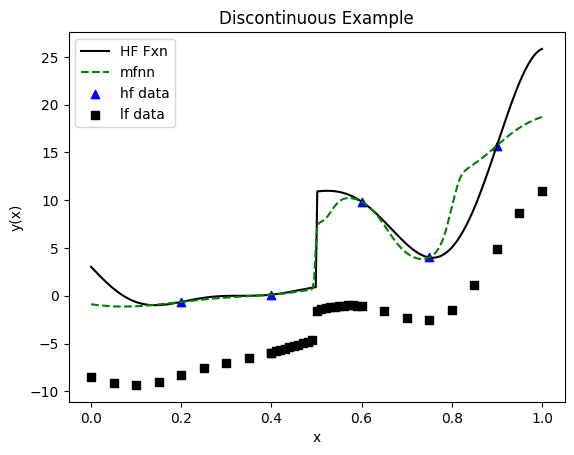

In [39]:
x_samp_tensor = torch.tensor(x_samp, dtype=DTYPE)
hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
mfnn_model.plot_model(x_samp_tensor, name=plot_name, color="green",label="mfnn",linestyle="dashed")
mfnn_model.plot_data(name = plot_name,color_lf="black", color_hf="blue",label_hf="hf data", label_lf="lf data")

Optimization terminated successfully.
         Current function value: 25.462495
         Iterations: 24
         Function evaluations: 48
[3.65313721]
Optimization terminated successfully.
         Current function value: 3.755538
         Iterations: 25
         Function evaluations: 50
Optimization terminated successfully.
         Current function value: 9.115727
         Iterations: 33
         Function evaluations: 88
[1574.]


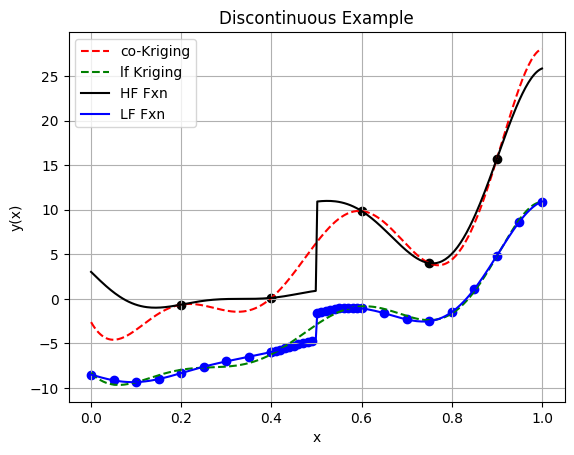

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import cokriging

# Start with a synthetic dataset
# rng = np.random.RandomState(0)
# fxn_ind = 1
# dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

# n_lf = 11
# n_hf = 4

# x_lf = np.zeros((n_lf,dim), dtype=float)
# x_hf = np.zeros((n_hf,dim), dtype=float)

# # Generate the analytical functions
# hf_fxn = mfs_functions.expensive_fxn(1)
# lf_fxn = mfs_functions.cheap_fxn(1)


# x_lf[:,0] = np.linspace(xmin,xmax,n_lf)
# y_lf = lf_fxn.evaluate(x_lf)
# x_hf[:,0] = np.linspace(xmin,xmax,n_hf)
# y_hf = hf_fxn.evaluate(x_hf)
cokriging_model = cokriging.CoKriging(x_lf=X_lf,
                            y_lf=y_lf,
                            x_hf=X_hf,
                            y_hf=y_hf,
                            scale_fixed=True)

cokriging_model.plot_model(x_samp,name=plot_name,color="red",label="co-Kriging",linestyle="dashed")

cokriging_model.kriging_lf.plot_model(x_samp, name=plot_name,color="green",label="lf Kriging", linestyle="dashed")

hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
lf_fxn.plot_model(x_samp, name=plot_name, color="blue", label="LF Fxn", linestyle="solid")

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()

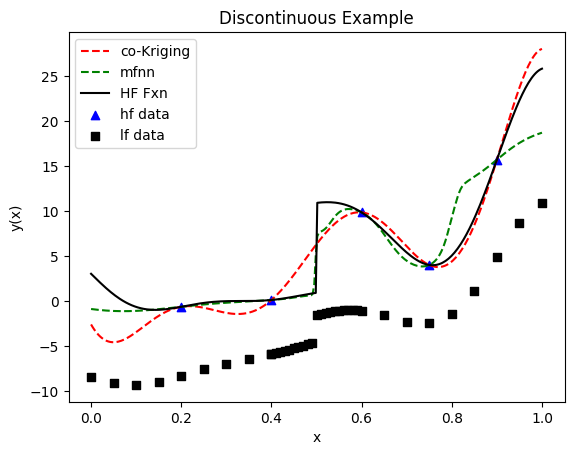

In [41]:
cokriging_model.plot_model(x_samp,name=plot_name,color="red",label="co-Kriging",linestyle="dashed")
mfnn_model.plot_model(x_samp_tensor, name=plot_name, color="green",label="mfnn",linestyle="dashed")
hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
mfnn_model.plot_data(name = plot_name,color_lf="black", color_hf="blue",label_hf="hf data", label_lf="lf data")

### Periodic Function Fit

Another example from the Meng paper.

In [ ]:
from SurrogateModels import mfs_functions

rng = np.random.RandomState(0)
fxn_ind = 7
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n_lf = 51
n_hf = 14

X_lf = np.zeros((n_lf,dim), dtype=float)
X_hf = np.zeros((n_hf,dim), dtype=float)

# Generate the analytical functions
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)

X_lf[:,0] = np.linspace(xmin,xmax,n_lf)
y_lf = lf_fxn.evaluate(X_lf)
X_hf[:,0] = np.linspace(xmin,xmax,n_hf)
y_hf = hf_fxn.evaluate(X_hf)

x_samp = np.ones((300,1))
x_samp[:,0] = np.linspace(0,1,300)

plot_name = "Periodic Example"

hf_fxn.plot_model(x_samp, name=plot_name, color="black", label="HF Fxn", linestyle="solid")
lf_fxn.plot_model(x_samp, name=plot_name, color="blue", label="LF Fxn", linestyle="solid")

plt.figure(plot_name)
plt.title(plot_name)
plt.scatter(X_hf, y_hf, color = "black", label = "HF samples", marker = "o")
plt.scatter(X_lf, y_lf, color = "blue", label = "LF samples", marker = "o")

plt.grid()
plt.show()